# Week 1: Data Acquisition, Cleaning, and Preprocessing
## Titanic passenger dataset

**Objective:** Acquire a public dataset, assess its quality, clean missing and invalid values, investigate outliers, preprocess fields, and validate the resulting dataset.

Dataset source: https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv

In [28]:
from pathlib import Path
import urllib.request
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
DATA_PATH = Path("raw_titanic.csv")
if not DATA_PATH.exists():
    urllib.request.urlretrieve(URL, DATA_PATH)
df = pd.read_csv(DATA_PATH)
print("Loaded:", df.shape)
display(df.head())


Loaded: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Initial exploration Inspect dimensions, column names, data types, summary statistics, missing values, and duplicate rows before making changes.

In [29]:
print("Shape:", df.shape)
print("\\nColumns:", df.columns.tolist())
display(df.dtypes.rename("dtype").to_frame())
display(df.describe(include="all").T)
missing_before = df.isna().sum().sort_values(ascending=False)
display(missing_before.rename("missing_count").to_frame())
print("Exact duplicate rows:", df.duplicated().sum())


Shape: (891, 15)
\nColumns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


,dtype
survived,int64
pclass,int64
sex,str
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,str
class,str
who,str


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count
deck,688
age,177
embarked,2
embark_town,2
survived,0
pclass,0
sex,0
sibsp,0
parch,0
fare,0


Exact duplicate rows: 107


## 2. Cleaning strategy Retain all original rows and keep exact matching rows for review rather than automatically removing them. Trim whitespace from strings. Validate plausible ranges for age, fare, passenger class, survival labels, and family counts. Invalid values are marked missing so that they can be handled explicitly.

In [30]:
clean = df.copy()
for col in clean.select_dtypes(include=["object", "str"]).columns:
    clean[col] = clean[col].map(lambda x: x.strip() if isinstance(x, str) else x)

if "age" in clean:
    clean.loc[(clean["age"] < 0) | (clean["age"] > 100), "age"] = np.nan
if "fare" in clean:
    clean.loc[clean["fare"] < 0, "fare"] = np.nan
if "survived" in clean:
    clean.loc[~clean["survived"].isin([0, 1]), "survived"] = np.nan
if "pclass" in clean:
    clean.loc[~clean["pclass"].isin([1, 2, 3]), "pclass"] = np.nan
for col in ["sibsp", "parch"]:
    if col in clean:
        clean.loc[clean[col] < 0, col] = np.nan

display(clean.isna().sum().sort_values(ascending=False).rename("missing_after_validation").to_frame())


,missing_after_validation
deck,688
age,177
embarked,2
embark_town,2
survived,0
pclass,0
sex,0
sibsp,0
parch,0
fare,0


## 3. Missing-value treatment Age is filled with its median as a robust baseline. The small number of missing embarkation categories are filled with their mode. Cabin/deck fields are assigned `Unknown` rather than deleting many rows or inventing a cabin. If the survival target is missing, it is deliberately not imputed.

In [31]:
if "age" in clean and clean["age"].isna().any():
    clean["age"] = clean["age"].fillna(clean["age"].median())
for col in ["embarked", "embark_town"]:
    if col in clean and clean[col].isna().any():
        mode = clean[col].mode(dropna=True)
        if len(mode):
            clean[col] = clean[col].fillna(mode.iloc[0])
for col in ["deck", "cabin"]:
    if col in clean and clean[col].isna().any():
        clean[col] = clean[col].fillna("Unknown")

for col in clean.columns:
    if clean[col].isna().any() and col != "survived":
        if pd.api.types.is_numeric_dtype(clean[col]):
            clean[col] = clean[col].fillna(clean[col].median())
        else:
            clean[col] = clean[col].fillna("Unknown")


## 4. Outlier investigation. The IQR rule identifies unusual values for review. Outliers are not automatically deleted: high fares may be legitimate and can reflect passenger class. The rule is a flag, not proof of an error.

In [32]:
outlier_summary = {}
for col in ["age", "fare"]:
    if col in clean and pd.api.types.is_numeric_dtype(clean[col]):
        q1, q3 = clean[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (clean[col] < lower) | (clean[col] > upper)
        outlier_summary[col] = {
            "q1": float(q1), "q3": float(q3), "iqr": float(iqr),
            "lower_fence": float(lower), "upper_fence": float(upper),
            "flagged_count": int(mask.sum())
        }
print(json.dumps(outlier_summary, indent=2))


{
  "age": {
    "q1": 22.0,
    "q3": 35.0,
    "iqr": 13.0,
    "lower_fence": 2.5,
    "upper_fence": 54.5,
    "flagged_count": 66
  },
  "fare": {
    "q1": 7.9104,
    "q3": 31.0,
    "iqr": 23.0896,
    "lower_fence": -26.724,
    "upper_fence": 65.6344,
    "flagged_count": 116
  }
}


## 5. Preprocessing and validation Selected binary/integer fields are cast to integer when complete; commonly categorical fields are cast to category. Missingness and duplicate counts are checked after cleaning. Any remaining missing survival labels should be reviewed rather than fabricated.

In [33]:
for col in ["survived", "pclass", "sibsp", "parch"]:
    if col in clean and clean[col].notna().all():
        clean[col] = clean[col].astype("int64")
for col in ["sex", "embarked", "class", "who", "deck", "embark_town", "alive"]:
    if col in clean:
        clean[col] = clean[col].astype("category")

print("Original shape:", df.shape)
print("Cleaned shape:", clean.shape)
print("Duplicate rows after cleaning:", clean.duplicated().sum())
display(clean.isna().sum().rename("missing_after_cleaning").to_frame())
display(clean.head())


Original shape: (891, 15)
Cleaned shape: (891, 15)
Duplicate rows after cleaning: 110


,missing_after_cleaning
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Unknown,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Unknown,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Unknown,Southampton,no,True


## 6. Visual evidence and export Charts help identify distribution shape and potential outliers. Run this cell to save charts and the cleaned CSV.

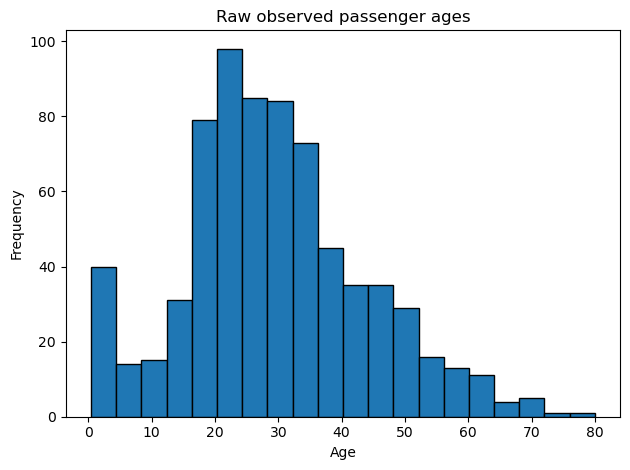

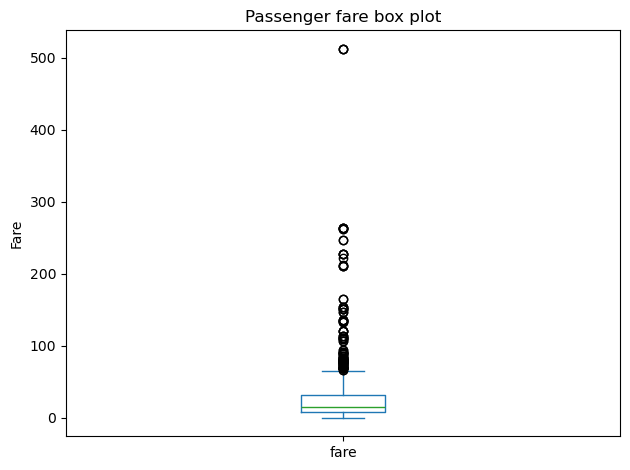

{
  "source_url": "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv",
  "initial_shape": [
    891,
    15
  ],
  "final_shape": [
    891,
    15
  ],
  "duplicates_before": 107,
  "duplicates_after": 110,
  "missing_before": {
    "survived": 0,
    "pclass": 0,
    "sex": 0,
    "age": 177,
    "sibsp": 0,
    "parch": 0,
    "fare": 0,
    "embarked": 2,
    "class": 0,
    "who": 0,
    "adult_male": 0,
    "deck": 688,
    "embark_town": 2,
    "alive": 0,
    "alone": 0
  },
  "missing_after": {
    "survived": 0,
    "pclass": 0,
    "sex": 0,
    "age": 0,
    "sibsp": 0,
    "parch": 0,
    "fare": 0,
    "embarked": 0,
    "class": 0,
    "who": 0,
    "adult_male": 0,
    "deck": 0,
    "embark_town": 0,
    "alive": 0,
    "alone": 0
  },
  "outlier_summary": {
    "age": {
      "q1": 22.0,
      "q3": 35.0,
      "iqr": 13.0,
      "lower_fence": 2.5,
      "upper_fence": 54.5,
      "flagged_count": 66
    },
    "fare": {
      "q1": 7.9104,
  

In [34]:
df["age"].dropna().plot(kind="hist", bins=20, edgecolor="black", title="Raw observed passenger ages")
plt.xlabel("Age")
plt.tight_layout()
plt.savefig("age_distribution.png", dpi=160)
plt.show()

df["fare"].dropna().plot(kind="box", title="Passenger fare box plot")
plt.ylabel("Fare")
plt.tight_layout()
plt.savefig("fare_boxplot.png", dpi=160)
plt.show()

clean.to_csv("cleaned_dataset.csv", index=False)
pd.DataFrame({"missing_count": df.isna().sum()}).to_csv("missing_values_before.csv")
pd.DataFrame({"missing_count": clean.isna().sum()}).to_csv("missing_values_final.csv")
summary = {
    "source_url": URL,
    "initial_shape": list(df.shape),
    "final_shape": list(clean.shape),
    "duplicates_before": int(df.duplicated().sum()),
    "duplicates_after": int(clean.duplicated().sum()),
    "missing_before": {k: int(v) for k, v in df.isna().sum().items()},
    "missing_after": {k: int(v) for k, v in clean.isna().sum().items()},
    "outlier_summary": outlier_summary
}
Path("cleaning_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))


## Reflection and Discussion

During this project, I learned that data cleaning is an important step before performing data analysis. Missing values, duplicate records, inconsistent entries, and unusual values can affect the accuracy of analytical results.

I used median imputation for missing age values because the median is less affected by extreme values than the mean. However, this method may reduce variation in the age data. For categorical fields with a small number of missing values, mode imputation was used where appropriate.

The cabin and deck fields contained missing information. Instead of deleting all records with missing cabin details, I represented the missing information as `Unknown`. This helped preserve passenger records for further analysis.

I used the interquartile range (IQR) method to identify potential outliers in numerical columns such as age and fare. I did not automatically remove these observations because some extreme values may be legitimate. Additional information about passenger class and ticket details would help determine whether an unusual fare represents an error.

These preprocessing decisions may affect future survival analysis and machine-learning models. Therefore, it is important to validate the cleaned dataset, understand the limitations of the chosen methods, and interpret the results carefully.

## Conclusion
The data is ready for exploratory analysis after the cleaning rules have been reviewed. Before using it for prediction, split training and test data first and fit imputation/encoding/scaling transformations on training data only to avoid leakage. For an academic submission, discuss the actual counts printed by the notebook rather than assuming fixed values.